# 01 – Exploratory Data Analysis

**Project:** Energy-Aware Early Fault Detection in Semiconductor Wafer Fabrication (UCI SECOM)

This notebook describes the raw SECOM data and flags the problems later notebooks must handle:

1. Class balance
2. Missing values per feature
3. Constant features
4. Highly correlated feature pairs (|r| > 0.95)
5. Skewness
6. Outliers (> 3 SD from the feature mean)
7. Fail rate by month
8. Top 10 features by correlation with the label
9. Summary table of key numbers

All charts are saved at 300 dpi to `outputs/figures/` with the prefix `01_`.

> **Leakage note:** this EDA uses the whole dataset to *describe* it. Any decision that changes the data
> (dropping features, imputing, scaling, selecting) must be re-fitted on the **training split only** in
> 02_Preprocessing / 03_Feature_Selection.

In [1]:
import sys
from pathlib import Path

# Make the project root importable so `src` works from notebooks/
ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from src.config import RANDOM_STATE, OUTPUTS_DIR
from src.data_loader import load_secom, split_xy
from src.plotting import (apply_style, save_fig, PASS_COLOR, FAIL_COLOR, NEUTRAL_COLOR,
                          REF_LINE_COLOR, TEXT_SECONDARY, SURFACE)

np.random.seed(RANDOM_STATE)
apply_style()
pd.set_option('display.width', 120)

df = load_secom()
X, y = split_xy(df)
summary = {}   # key numbers collected along the way, printed at the end
print(f'Rows: {df.shape[0]}  |  Sensor features: {X.shape[1]}')
df.iloc[:5, :8]

Rows: 1567  |  Sensor features: 590


,orig_index,timestamp,label,f000,f001,f002,f003,f004
0,0,2008-07-19 11:55:00,0,3030.93,2564.00,2187.7333,1411.1265,1.3602
1,1,2008-07-19 12:32:00,0,3095.78,2465.14,2230.4222,1463.6606,0.8294
2,2,2008-07-19 13:17:00,1,2932.61,2559.94,2186.4111,1698.0172,1.5102
3,3,2008-07-19 14:43:00,0,2988.72,2479.90,2199.0333,909.7926,1.3204
4,4,2008-07-19 15:22:00,0,3032.24,2502.87,2233.3667,1326.5200,1.5334


## 1. Class balance

   class  count  percent
Pass (0)   1463    93.36
Fail (1)    104     6.64

Imbalance ratio (pass : fail) = 14.07 : 1


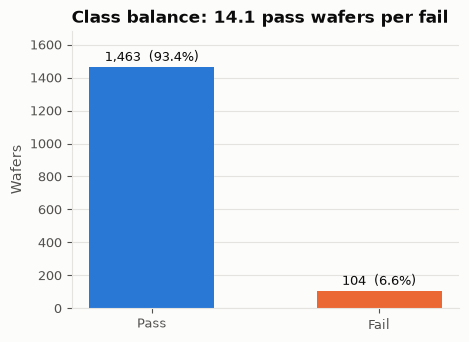

In [2]:
counts = y.value_counts().sort_index()          # 0 = pass, 1 = fail
pct = counts / counts.sum() * 100
ratio = counts[0] / counts[1]

balance = pd.DataFrame({'class': ['Pass (0)', 'Fail (1)'], 'count': counts.values,
                        'percent': pct.round(2).values})
print(balance.to_string(index=False))
print(f'\nImbalance ratio (pass : fail) = {ratio:.2f} : 1')

summary['Wafers (rows)'] = len(df)
summary['Sensor features'] = X.shape[1]
summary['Pass wafers'] = int(counts[0])
summary['Fail wafers'] = int(counts[1])
summary['Fail rate (%)'] = round(pct[1], 2)
summary['Imbalance ratio (pass:fail)'] = f'{ratio:.2f} : 1'

fig, ax = plt.subplots(figsize=(5, 3.6))
bars = ax.bar(['Pass', 'Fail'], counts.values, color=[PASS_COLOR, FAIL_COLOR], width=0.55)
for b, c, p in zip(bars, counts.values, pct.values):
    ax.text(b.get_x() + b.get_width() / 2, c + 20, f'{c:,}  ({p:.1f}%)', ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Wafers')
ax.set_title(f'Class balance: {ratio:.1f} pass wafers per fail')
ax.set_ylim(0, counts.max() * 1.15)
ax.grid(axis='x', visible=False)
save_fig(fig, '01_class_balance')
plt.show()

Only about 1 wafer in 15 fails. Accuracy is therefore meaningless (predicting "pass" for everything is ~93% accurate);
we evaluate with recall, precision, PR-AUC and the energy-aware cost metric, and handle imbalance with
class weights or resampling on the training data only.

## 2. Missing values per feature

Total missing cells        : 41,951 (4.54% of all cells)
Features with any missing  : 538
Features with >50% missing : 28
Features with >80% missing : 8
Rows with any missing      : 1567 of 1567

Most-missing features:
f292    91.2
f293    91.2
f158    91.2
f157    91.2
f492    85.6
f085    85.6
f358    85.6
f220    85.6
f244    65.0
f517    65.0


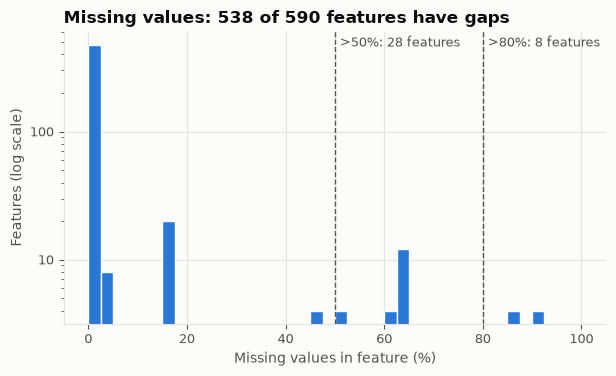

In [3]:
missing_pct = X.isna().mean() * 100
n_missing_any = int((missing_pct > 0).sum())
n_over50 = int((missing_pct > 50).sum())
n_over80 = int((missing_pct > 80).sum())
total_missing_pct = X.isna().values.mean() * 100

print(f'Total missing cells        : {int(X.isna().values.sum()):,} ({total_missing_pct:.2f}% of all cells)')
print(f'Features with any missing  : {n_missing_any}')
print(f'Features with >50% missing : {n_over50}')
print(f'Features with >80% missing : {n_over80}')
print(f'Rows with any missing      : {int(X.isna().any(axis=1).sum())} of {len(X)}')
print('\nMost-missing features:')
print(missing_pct.sort_values(ascending=False).head(10).round(1).to_string())

summary['Missing cells (% of all)'] = round(total_missing_pct, 2)
summary['Features with any missing'] = n_missing_any
summary['Features >50% missing'] = n_over50
summary['Features >80% missing'] = n_over80

fig, ax = plt.subplots(figsize=(7, 3.8))
bins = np.arange(0, 102.5, 2.5)
ax.hist(missing_pct[missing_pct > 0], bins=bins, color=NEUTRAL_COLOR, edgecolor='white', linewidth=1)
for t, n in [(50, n_over50), (80, n_over80)]:
    ax.axvline(t, color=REF_LINE_COLOR, linestyle='--', linewidth=1)
    ax.text(t + 1, ax.get_ylim()[1] * 0.92, f'>{t}%: {n} features', fontsize=9, color=TEXT_SECONDARY)
ax.set_yscale('log')
ax.yaxis.set_major_formatter(mtick.ScalarFormatter())
ax.set_xlabel('Missing values in feature (%)')
ax.set_ylabel('Features (log scale)')
ax.set_title(f'Missing values: {n_missing_any} of {X.shape[1]} features have gaps')
save_fig(fig, '01_missing_values_hist')
plt.show()

Missingness is concentrated: most features with gaps are missing well under 5% of values and can be imputed, while
28 features are missing more than half their values (8 of them more than 80%). Those carry little information and
are candidates to drop (threshold decided on the training split). Every wafer has at least one missing value, so
dropping rows is not an option.

## 3. Constant features

A feature is **constant** if it has a single unique non-missing value (zero variance). It cannot help any model.

In [4]:
nunique = X.nunique(dropna=True)
constant_cols = nunique[nunique <= 1].index.tolist()
non_constant_cols = [c for c in X.columns if c not in constant_cols]

print(f'Constant features: {len(constant_cols)}')
print(f'Non-constant features remaining: {len(non_constant_cols)}')
print('Examples:', constant_cols[:15])

summary['Constant features'] = len(constant_cols)
summary['Non-constant features'] = len(non_constant_cols)

Xn = X[non_constant_cols]   # used for the remaining feature-level analyses

Constant features: 116
Non-constant features remaining: 474
Examples: ['f005', 'f013', 'f042', 'f049', 'f052', 'f069', 'f097', 'f141', 'f149', 'f178', 'f179', 'f186', 'f189', 'f190', 'f191']


## 4. Highly correlated feature pairs (|r| > 0.95)

Pearson correlation between every pair of non-constant features (pairwise-complete observations).

Feature pairs evaluated : 111,933
Pairs with |r| > 0.95   : 329
Features involved       : 309

Top 10 pairs:
feature_a feature_b   r
     f492      f545 1.0
     f358      f544 1.0
     f209      f342 1.0
     f209      f347 1.0
     f342      f347 1.0
     f579      f587 1.0
     f074      f342 1.0
     f074      f478 1.0
     f074      f209 1.0
     f580      f588 1.0


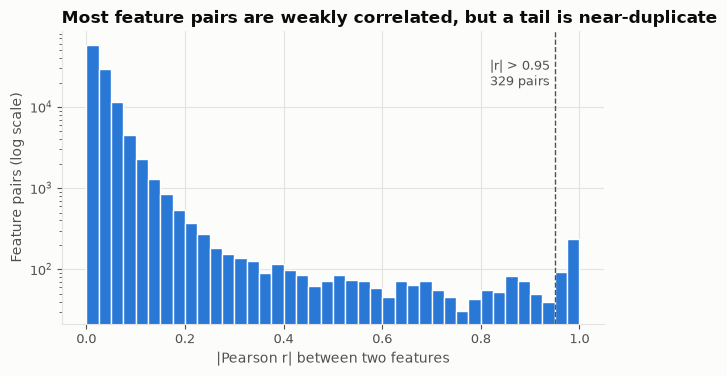

In [5]:
corr = Xn.corr(method='pearson')
iu = np.triu_indices_from(corr, k=1)
pairs = pd.DataFrame({'feature_a': corr.index[iu[0]], 'feature_b': corr.columns[iu[1]],
                      'r': corr.values[iu]}).dropna()
pairs['abs_r'] = pairs['r'].abs()

high_pairs = pairs[pairs['abs_r'] > 0.95].sort_values('abs_r', ascending=False)
features_in_high = pd.unique(high_pairs[['feature_a', 'feature_b']].values.ravel())

print(f'Feature pairs evaluated : {len(pairs):,}')
print(f'Pairs with |r| > 0.95   : {len(high_pairs)}')
print(f'Features involved       : {len(features_in_high)}')
print('\nTop 10 pairs:')
print(high_pairs.head(10)[['feature_a', 'feature_b', 'r']].round(4).to_string(index=False))

summary['Highly correlated pairs (|r|>0.95)'] = len(high_pairs)
summary['Features in a |r|>0.95 pair'] = len(features_in_high)

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.hist(pairs['abs_r'], bins=np.arange(0, 1.0001, 0.025), color=NEUTRAL_COLOR, edgecolor='white', linewidth=1)
ax.axvline(0.95, color=REF_LINE_COLOR, linestyle='--', linewidth=1)
ax.text(0.94, ax.get_ylim()[1] * 0.3, f'|r| > 0.95\n{len(high_pairs)} pairs', ha='right', fontsize=9, color=TEXT_SECONDARY)
ax.set_yscale('log')
ax.set_xlabel('|Pearson r| between two features')
ax.set_ylabel('Feature pairs (log scale)')
ax.set_title('Most feature pairs are weakly correlated, but a tail is near-duplicate')
save_fig(fig, '01_feature_correlation_hist')
plt.show()

Pairs above 0.95 are near-duplicate sensors (often the same signal measured or derived twice). Keeping one of each
pair reduces dimensionality and, in an energy-aware framing, the number of sensors that need to be monitored.

## 5. Skewness

Rule of thumb: |skew| ≤ 0.5 roughly symmetric, 0.5–1 moderate, > 1 highly skewed.

Approximately symmetric (|skew| <= 0.5): 99
Moderately skewed (0.5 < |skew| <= 1) : 53
Highly skewed (|skew| > 1)            : 322
Median |skew|: 2.54   Max |skew|: 39.6

Most skewed features:
f390    39.56
f252    39.56
f287    39.52
f152    39.52
f209    39.51
f074    39.51
f478    39.51
f342    39.51
f347    39.51
f206    39.51


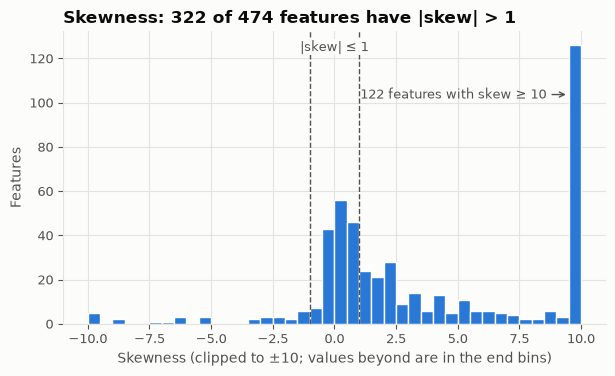

In [6]:
skew = Xn.skew(skipna=True).dropna()
n_sym = int((skew.abs() <= 0.5).sum())
n_mod = int(((skew.abs() > 0.5) & (skew.abs() <= 1)).sum())
n_high = int((skew.abs() > 1).sum())

print(f'Approximately symmetric (|skew| <= 0.5): {n_sym}')
print(f'Moderately skewed (0.5 < |skew| <= 1) : {n_mod}')
print(f'Highly skewed (|skew| > 1)            : {n_high}')
print(f'Median |skew|: {skew.abs().median():.2f}   Max |skew|: {skew.abs().max():.1f}')
print('\nMost skewed features:')
print(skew.reindex(skew.abs().sort_values(ascending=False).index).head(10).round(2).to_string())

summary['Highly skewed features (|skew|>1)'] = n_high
summary['Median |skew|'] = round(skew.abs().median(), 2)

fig, ax = plt.subplots(figsize=(7, 3.8))
clipped = skew.clip(-10, 10)
ax.hist(clipped, bins=np.arange(-10, 10.5, 0.5), color=NEUTRAL_COLOR, edgecolor='white', linewidth=1)
for t in (-1, 1):
    ax.axvline(t, color=REF_LINE_COLOR, linestyle='--', linewidth=1)
n_ge10 = int((skew >= 10).sum())
ax.annotate(f'{n_ge10} features with skew ≥ 10', xy=(9.5, n_ge10 * 0.85), xytext=(8.6, n_ge10 * 0.85),
            fontsize=9, color=TEXT_SECONDARY, va='center', ha='right',
            arrowprops=dict(arrowstyle='->', color=REF_LINE_COLOR, linewidth=1))
ax.text(0, ax.get_ylim()[1] * 0.97, '|skew| ≤ 1', ha='center', va='top', fontsize=9, color=TEXT_SECONDARY,
        bbox=dict(facecolor=SURFACE, edgecolor='none', pad=1), zorder=3)
ax.set_xlabel('Skewness (clipped to ±10; values beyond are in the end bins)')
ax.set_ylabel('Features')
ax.set_title(f'Skewness: {n_high} of {len(skew)} features have |skew| > 1')
save_fig(fig, '01_skewness_hist')
plt.show()

About two-thirds of the non-constant sensors are highly skewed, almost all to the right (long tails / spikes);
a large group has skew ≥ 10, typical of a mostly-flat signal with rare spikes. Distance- and linear-based models benefit from
robust scaling or log/Yeo-Johnson transforms; tree models (Random Forest, XGBoost) are insensitive to this.

## 6. Outliers (> 3 SD)

A value is flagged as an outlier if it lies more than 3 standard deviations from its feature's mean
(computed on non-missing values).

Outlier values            : 6,116 (0.87% of non-missing values)
Features with >=1 outlier : 440 of 474
Wafers with >=1 outlier   : 1265 of 1567

Mean outlier values per wafer by class:
label
pass    3.78
fail    5.62

Features with the highest share of outliers (%):
f038    4.53
f576    4.47
f574    4.34
f577    3.96
f572    3.83
f573    3.83
f575    3.64
f558    3.58
f295    3.45
f160    3.45


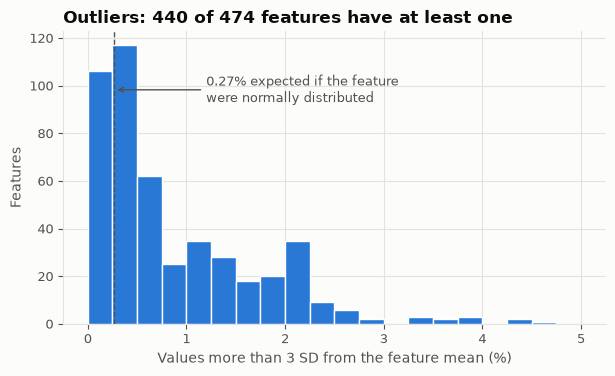

In [7]:
z = (Xn - Xn.mean()) / Xn.std()
is_out = z.abs() > 3
out_per_feature = is_out.sum()
out_pct_per_feature = out_per_feature / Xn.notna().sum() * 100
total_out = int(out_per_feature.sum())
total_obs = int(Xn.notna().values.sum())
n_feat_with_out = int((out_per_feature > 0).sum())
rows_with_out = int(is_out.any(axis=1).sum())

print(f'Outlier values            : {total_out:,} ({total_out / total_obs * 100:.2f}% of non-missing values)')
print(f'Features with >=1 outlier : {n_feat_with_out} of {Xn.shape[1]}')
print(f'Wafers with >=1 outlier   : {rows_with_out} of {len(Xn)}')

# Are outliers more common in failing wafers?
out_per_row = is_out.sum(axis=1)
print('\nMean outlier values per wafer by class:')
print(out_per_row.groupby(y).mean().rename({0: 'pass', 1: 'fail'}).round(2).to_string())
print('\nFeatures with the highest share of outliers (%):')
print(out_pct_per_feature.sort_values(ascending=False).head(10).round(2).to_string())

summary['Outlier values >3 SD (% of observed)'] = round(total_out / total_obs * 100, 2)
summary['Features with >=1 outlier'] = n_feat_with_out
summary['Wafers with >=1 outlier'] = rows_with_out

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.hist(out_pct_per_feature, bins=np.arange(0, out_pct_per_feature.max() + 0.5, 0.25),
        color=NEUTRAL_COLOR, edgecolor='white', linewidth=1)
ax.axvline(0.27, color=REF_LINE_COLOR, linestyle='--', linewidth=1)
ymax = ax.get_ylim()[1]
ax.annotate('0.27% expected if the feature\nwere normally distributed', xy=(0.27, ymax * 0.8), xytext=(1.2, ymax * 0.8),
            fontsize=9, color=TEXT_SECONDARY, va='center',
            arrowprops=dict(arrowstyle='->', color=REF_LINE_COLOR, linewidth=1))
ax.set_xlabel('Values more than 3 SD from the feature mean (%)')
ax.set_ylabel('Features')
ax.set_title(f'Outliers: {n_feat_with_out} of {Xn.shape[1]} features have at least one')
save_fig(fig, '01_outliers_hist')
plt.show()

Outliers are spread across most features, and failing wafers have more extreme readings on average than passing
ones. Because a fault can show up exactly as an extreme reading, we do **not** delete outlier rows; instead we use robust scaling and tree-based models that are not distorted by extremes.

## 7. Fail rate by month

         wafers  fails  fail_rate_pct
month                                
2008-07      63     14          22.22
2008-08     555     51           9.19
2008-09     590     17           2.88
2008-10     359     22           6.13


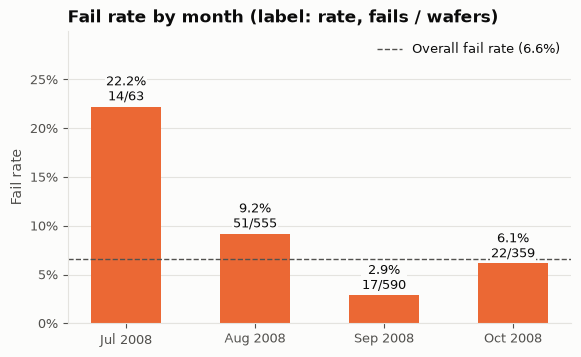

In [8]:
month = df['timestamp'].dt.to_period('M').rename('month')
monthly = df.groupby(month)['label'].agg(wafers='size', fails='sum')
monthly['fail_rate_pct'] = (monthly['fails'] / monthly['wafers'] * 100).round(2)
print(monthly.to_string())

overall_rate = y.mean() * 100
summary['Date range'] = f"{df['timestamp'].min():%d %b %Y} to {df['timestamp'].max():%d %b %Y}"
summary['Months covered'] = len(monthly)
summary['Highest monthly fail rate (%)'] = f"{monthly['fail_rate_pct'].max():.2f} ({monthly['fail_rate_pct'].idxmax()})"
summary['Lowest monthly fail rate (%)'] = f"{monthly['fail_rate_pct'].min():.2f} ({monthly['fail_rate_pct'].idxmin()})"

fig, ax = plt.subplots(figsize=(6.5, 3.8))
labels = [p.strftime('%b %Y') for p in monthly.index]
bars = ax.bar(labels, monthly['fail_rate_pct'], color=FAIL_COLOR, width=0.55)
for b, (_, r) in zip(bars, monthly.iterrows()):
    ax.text(b.get_x() + b.get_width() / 2, r['fail_rate_pct'] + 0.2,
            f"{r['fail_rate_pct']:.1f}%\n{int(r['fails'])}/{int(r['wafers'])}", ha='center', va='bottom', fontsize=9,
            bbox=dict(facecolor=SURFACE, edgecolor='none', pad=1), zorder=3)
ax.axhline(overall_rate, color=REF_LINE_COLOR, linestyle='--', linewidth=1,
           label=f'Overall fail rate ({overall_rate:.1f}%)')
ax.legend(loc='upper right')
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylim(0, monthly['fail_rate_pct'].max() * 1.35)
ax.set_ylabel('Fail rate')
ax.set_title('Fail rate by month (label: rate, fails / wafers)')
ax.grid(axis='x', visible=False)
save_fig(fig, '01_fail_rate_by_month')
plt.show()

The data covers about three months (July and October are partial months) and the fail rate drifts strongly between
months, from 22% in the short July period down to under 3% in September. This supports a **time-ordered train/test split** in 02_Preprocessing, so the model is tested on
later wafers than it was trained on, as it would be in the fab.

## 8. Top 10 features by correlation with the label

Point-biserial correlation (Pearson r between each feature and the 0/1 label), ranked by |r|.

           r     |r|  missing_%
f059  0.1558  0.1558        0.4
f103  0.1512  0.1512        0.1
f510  0.1316  0.1316        0.1
f348  0.1302  0.1302        1.5
f158  0.1213  0.1213       91.2
f431  0.1209  0.1209        0.1
f293  0.1145  0.1145       91.2
f111 -0.1139  0.1139       65.0
f434  0.1121  0.1121        0.1
f430  0.1101  0.1101        0.1

Max |r| with label: 0.156 - no single sensor is a strong predictor on its own.


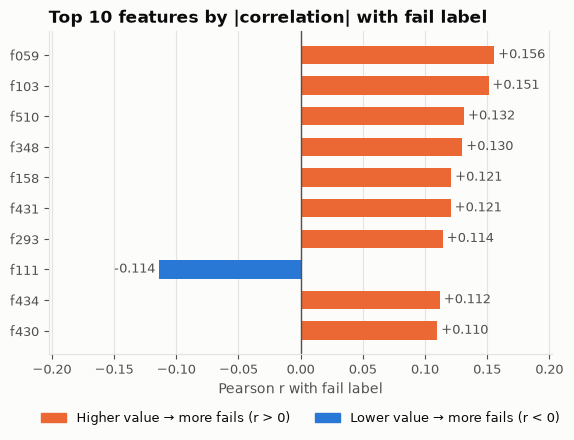

In [9]:
label_corr = Xn.corrwith(y).dropna()
top10 = label_corr.reindex(label_corr.abs().sort_values(ascending=False).index).head(10)
top10_table = pd.DataFrame({'r': top10.round(4), '|r|': top10.abs().round(4),
                            'missing_%': missing_pct[top10.index].round(1)})
print(top10_table.to_string())
print(f'\nMax |r| with label: {label_corr.abs().max():.3f} - no single sensor is a strong predictor on its own.')

summary['Max |r| with label'] = round(label_corr.abs().max(), 3)
summary['Top feature by |r| with label'] = f'{top10.index[0]} (r = {top10.iloc[0]:.3f})'

fig, ax = plt.subplots(figsize=(6.5, 4.2))
plot = top10.iloc[::-1]
colors = [FAIL_COLOR if v > 0 else PASS_COLOR for v in plot.values]
ax.barh(plot.index, plot.values, color=colors, height=0.6)
for i, v in enumerate(plot.values):
    ax.text(v + (0.003 if v >= 0 else -0.003), i, f'{v:+.3f}', va='center',
            ha='left' if v >= 0 else 'right', fontsize=9, color=TEXT_SECONDARY)
ax.axvline(0, color=REF_LINE_COLOR, linewidth=1)
lim = top10.abs().max() * 1.3
ax.set_xlim(-lim if (top10 < 0).any() else 0, lim)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=FAIL_COLOR, label='Higher value → more fails (r > 0)'),
                   Patch(color=PASS_COLOR, label='Lower value → more fails (r < 0)')],
          loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=2)
ax.set_xlabel('Pearson r with fail label')
ax.set_title('Top 10 features by |correlation| with fail label')
ax.grid(axis='y', visible=False)
save_fig(fig, '01_top10_label_correlation')
plt.show()

Correlations with the label are weak (all |r| below 0.2), so faults are not explained by any single sensor.
This motivates multivariate models and feature selection rather than simple per-sensor thresholds.

Caution: some top features (e.g. f158, f293, f111) are missing in 65–91% of wafers, so their r is computed on a small
subset and is unreliable. Check the `missing_%` column before trusting a feature's rank.

## 9. Summary of key numbers

In [10]:
summary_df = pd.DataFrame({'Metric': list(summary.keys()), 'Value': [str(v) for v in summary.values()]})
summary_path = OUTPUTS_DIR / '01_eda_summary.csv'
summary_df.to_csv(summary_path, index=False)

w = summary_df['Metric'].str.len().max()
print('SECOM EDA - key numbers')
print('=' * (w + 28))
for m, v in zip(summary_df['Metric'], summary_df['Value']):
    print(f'{m:<{w}}  {v}')
print('=' * (w + 28))
print(f'\nSaved to {summary_path.relative_to(ROOT)}')
print('Figures saved:', ', '.join(sorted(p.name for p in (OUTPUTS_DIR / 'figures').glob('01_*.png'))))

SECOM EDA - key numbers
Wafers (rows)                         1567
Sensor features                       590
Pass wafers                           1463
Fail wafers                           104
Fail rate (%)                         6.64
Imbalance ratio (pass:fail)           14.07 : 1
Missing cells (% of all)              4.54
Features with any missing             538
Features >50% missing                 28
Features >80% missing                 8
Constant features                     116
Non-constant features                 474
Highly correlated pairs (|r|>0.95)    329
Features in a |r|>0.95 pair           309
Highly skewed features (|skew|>1)     322
Median |skew|                         2.54
Outlier values >3 SD (% of observed)  0.87
Features with >=1 outlier             440
Wafers with >=1 outlier               1265
Date range                            19 Jul 2008 to 17 Oct 2008
Months covered                        4
Highest monthly fail rate (%)         22.22 (2008-07)
Lowest mo

### Implications for the next notebooks

- **Imbalance (~14:1):** use class weights / SMOTE on training folds only; evaluate with recall, PR-AUC and cost.
- **Missing values:** drop features above a missing-rate threshold (e.g. 50%), impute the rest (median) — fitted on train.
- **Constant & near-duplicate features:** drop constants; keep one feature from each |r| > 0.95 group.
- **Skew & outliers:** robust scaling or power transforms for linear models; keep outlier rows.
- **Time drift:** split by time, not randomly.
- **Weak individual signals:** rely on multivariate models and feature selection.